# **Exercise 4 · Give Me Some Credit**

### **Imports & Setup**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'FreeSerif', 'DejaVu Serif'],
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
})
SKY, SKY_EDGE = '#9AD0EC', '#5BA8D6'
YELLOW, YELLOW_EDGE = '#F8DC75', '#D9B93A'
GRAY = '#8A94A6'

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
from imblearn.over_sampling import SMOTENC
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
PASTEL = LinearSegmentedColormap.from_list('pastel', ['#FFFFFF', SKY])

### **Load the data**

In [2]:
raw = pd.read_csv('GiveMeSomeCredit.csv')
print('Shape:', raw.shape)
print('Default rate:', round(raw['SeriousDlqin'].mean(), 4))
print('Corr(NumberOfDefault, target):', round(raw['NumberOfDefault'].corr(raw['SeriousDlqin']), 3))
raw.isna().sum()[lambda s: s > 0].rename('missing').to_frame()

Shape: (149724, 14)
Default rate: 0.066
Corr(NumberOfDefault, target): 0.922


,missing
MonthlyIncome,29607
NumberOfDependents,3893


### **Q4 (a) · Prepare and export `train.csv` and `test.csv`**

In [3]:
data = raw.rename(columns={
    'RevolvingUtilizationOfUnsecuredLines': 'Utilization',
    'NumberOfTime30-59DaysPastDueNotWorse': 'Late30_59',
    'NumberOfTime60-89DaysPastDueNotWorse': 'Late60_89',
    'NumberOfTimes90DaysLate': 'Late90',
})
bad_age = ~data['age'].between(18, 100)
print('Rows with impossible age removed:', int(bad_age.sum()))
data = data[~bad_age].drop(columns=['NumberOfDefault', 'SEX']).reset_index(drop=True)

train_raw, test_raw = train_test_split(data, test_size=0.3, stratify=data['SeriousDlqin'], random_state=SEED)
fills = {'MonthlyIncome': train_raw['MonthlyIncome'].median(),
         'NumberOfDependents': train_raw['NumberOfDependents'].median()}
print('Fill values from training rows:', fills)


def add_features(frame):
    f = frame.copy()
    f['MonthlyIncome_missing'] = f['MonthlyIncome'].isna().astype(int)
    for col, value in fills.items():
        f[col] = f[col].fillna(value)
    f['TotalPastDue'] = f['Late30_59'] + f['Late60_89'] + f['Late90']
    f['Has90DaysLate'] = (f['Late90'] > 0).astype(int)
    return f


train, test = add_features(train_raw), add_features(test_raw)
train.to_csv('train.csv', index=False)
test.to_csv('test.csv', index=False)

TARGET = 'SeriousDlqin'
FEATURES = [c for c in train.columns if c != TARGET]
CATEGORICAL = ['EDUCATION', 'MonthlyIncome_missing', 'Has90DaysLate']
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print('Train:', train.shape, '| test:', test.shape, '| default rate train/test:',
      round(y_train.mean(), 4), '/', round(y_test.mean(), 4))
pd.read_csv('train.csv').head(3)

Rows with impossible age removed: 14
Fill values from training rows: {'MonthlyIncome': np.float64(5416.0), 'NumberOfDependents': np.float64(0.0)}
Train: (104797, 15) | test: (44913, 15) | default rate train/test: 0.066 / 0.066


,SeriousDlqin,Utilization,age,EDUCATION,Late30_59,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,Late90,NumberRealEstateLoansOrLines,Late60_89,NumberOfDependents,MonthlyIncome_missing,TotalPastDue,Has90DaysLate
0,0,0.203223,60,2,0,1600.000000,5416.0,8,0,1,0,0.0,1,0,0
1,0,1.000000,24,3,0,0.100074,1358.0,3,0,0,0,0.0,0,0,0
2,0,0.200152,49,1,0,0.224416,12917.0,8,0,1,0,0.0,0,0,0


### **Q4 (b) · Baseline random forest: precision, recall, F1, support**

In [4]:
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
proba_rf = rf.predict_proba(X_test)[:, 1]
pred_rf = (proba_rf >= 0.5).astype(int)
print('Accuracy:', round(accuracy_score(y_test, pred_rf), 4))
print('Accuracy of "everyone is good":', round(1 - y_test.mean(), 4))
print()
print(classification_report(y_test, pred_rf, target_names=['No default (0)', 'Default (1)'], digits=3))

Accuracy: 0.936
Accuracy of "everyone is good": 0.934

                precision    recall  f1-score   support

No default (0)      0.946     0.988     0.967     41950
   Default (1)      0.542     0.197     0.289      2963

      accuracy                          0.936     44913
     macro avg      0.744     0.593     0.628     44913
  weighted avg      0.919     0.936     0.922     44913



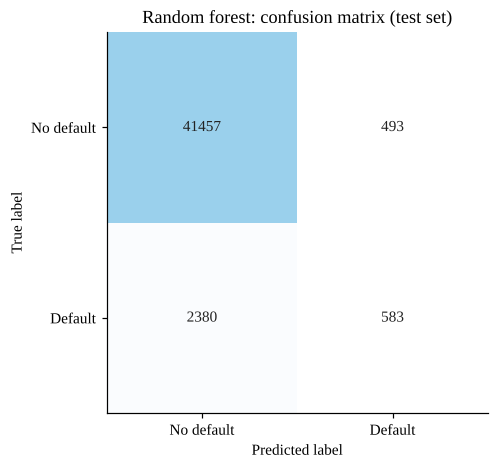

In [5]:
cm = confusion_matrix(y_test, pred_rf)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['No default', 'Default']).plot(
    ax=ax, cmap=PASTEL, colorbar=False, values_format='d')
ax.grid(False)
for t in ax.texts:
    t.set_color('#222222')
ax.set_title('Random forest: confusion matrix (test set)')
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
plt.show()

In [6]:
tn, fp, fn, tp = cm.ravel()
print(f'Defaulters in the test set: {tp + fn}')
print(f'Found: {tp} | missed: {fn} (recall {tp / (tp + fn):.1%})')

Defaulters in the test set: 2963
Found: 583 | missed: 2380 (recall 19.7%)


### **Q4 (c) · Trying to improve the model**

In [7]:
def evaluate(name, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {'model': name, 'accuracy': accuracy_score(y_test, pred),
            'precision (1)': precision_score(y_test, pred, zero_division=0),
            'recall (1)': recall_score(y_test, pred), 'F1 (1)': f1_score(y_test, pred),
            'balanced acc': balanced_accuracy_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, proba), 'PR-AUC': average_precision_score(y_test, proba)}


results = [evaluate('RF baseline', proba_rf)]
probas = {'RF baseline': proba_rf}

In [8]:
cat_idx = [FEATURES.index(c) for c in CATEGORICAL]
X_bal, y_bal = SMOTENC(categorical_features=cat_idx, random_state=SEED).fit_resample(X_train, y_train)
print('Training rows:', len(X_train), '->', len(X_bal), '| default share:', round(y_bal.mean(), 2))
rf_bal = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X_bal, y_bal)
probas['RF + SMOTENC'] = rf_bal.predict_proba(X_test)[:, 1]
results.append(evaluate('RF + SMOTENC', probas['RF + SMOTENC']))
pd.DataFrame(results).round(3)

Training rows: 104797 -> 195764 | default share: 0.5


,model,accuracy,precision (1),recall (1),F1 (1),balanced acc,ROC-AUC,PR-AUC
0,RF baseline,0.936,0.542,0.197,0.289,0.593,0.836,0.347
1,RF + SMOTENC,0.903,0.320,0.413,0.361,0.676,0.824,0.285


In [9]:
keep = IsolationForest(contamination=0.02, random_state=SEED).fit_predict(X_train) == 1
print('Rows removed:', int((~keep).sum()))
print('Default rate in removed rows:', round(y_train[~keep].mean(), 3), '| in kept rows:', round(y_train[keep].mean(), 3))
rf_out = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X_train[keep], y_train[keep])
probas['RF - outliers'] = rf_out.predict_proba(X_test)[:, 1]
results.append(evaluate('RF - outliers', probas['RF - outliers']))
pd.DataFrame(results).round(3)

Rows removed: 2096
Default rate in removed rows: 0.537 | in kept rows: 0.056


,model,accuracy,precision (1),recall (1),F1 (1),balanced acc,ROC-AUC,PR-AUC
0,RF baseline,0.936,0.542,0.197,0.289,0.593,0.836,0.347
1,RF + SMOTENC,0.903,0.320,0.413,0.361,0.676,0.824,0.285
2,RF - outliers,0.936,0.533,0.195,0.286,0.592,0.836,0.339


In [10]:
xgb = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, tree_method='hist', eval_metric='logloss',
                    random_state=SEED, n_jobs=2).fit(X_train, y_train)
probas['XGB default'] = xgb.predict_proba(X_test)[:, 1]
results.append(evaluate('XGB default', probas['XGB default']))
pd.DataFrame(results).round(3)

,model,accuracy,precision (1),recall (1),F1 (1),balanced acc,ROC-AUC,PR-AUC
0,RF baseline,0.936,0.542,0.197,0.289,0.593,0.836,0.347
1,RF + SMOTENC,0.903,0.320,0.413,0.361,0.676,0.824,0.285
2,RF - outliers,0.936,0.533,0.195,0.286,0.592,0.836,0.339
3,XGB default,0.937,0.560,0.194,0.289,0.592,0.853,0.367


In [11]:
space = {'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 4, 6], 'min_child_weight': [1, 5, 20],
         'subsample': [0.7, 0.9, 1.0], 'colsample_bytree': [0.7, 0.9, 1.0], 'reg_lambda': [1, 5, 10]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
base = XGBClassifier(n_estimators=300, tree_method='hist', eval_metric='logloss', random_state=SEED, n_jobs=2)

searches = {}
for metric in ['accuracy', 'average_precision']:
    s = RandomizedSearchCV(base, space, n_iter=12, scoring=metric, cv=cv, random_state=SEED, n_jobs=1)
    searches[metric] = s.fit(X_train, y_train)
    print(f'{metric:18s} best CV score: {s.best_score_:.4f} | {s.best_params_}')

accuracy           best CV score: 0.9379 | {'subsample': 1.0, 'reg_lambda': 1, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
average_precision  best CV score: 0.4006 | {'subsample': 0.9, 'reg_lambda': 10, 'min_child_weight': 20, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


In [12]:
best_acc = searches['accuracy'].best_estimator_
best_ap = searches['average_precision'].best_estimator_
probas['XGB tuned (accuracy)'] = best_acc.predict_proba(X_test)[:, 1]
probas['XGB tuned (PR-AUC)'] = best_ap.predict_proba(X_test)[:, 1]
results.append(evaluate('XGB tuned (accuracy)', probas['XGB tuned (accuracy)']))
results.append(evaluate('XGB tuned (PR-AUC)', probas['XGB tuned (PR-AUC)']))
pd.DataFrame(results).round(3)

,model,accuracy,precision (1),recall (1),F1 (1),balanced acc,ROC-AUC,PR-AUC
0,RF baseline,0.936,0.542,0.197,0.289,0.593,0.836,0.347
1,RF + SMOTENC,0.903,0.320,0.413,0.361,0.676,0.824,0.285
2,RF - outliers,0.936,0.533,0.195,0.286,0.592,0.836,0.339
3,XGB default,0.937,0.560,0.194,0.289,0.592,0.853,0.367
4,XGB tuned (accuracy),0.938,0.590,0.185,0.282,0.588,0.857,0.388
5,XGB tuned (PR-AUC),0.938,0.587,0.189,0.286,0.590,0.857,0.387


In [13]:
X_kept, y_kept = X_train[keep], y_train[keep]
X_all4, y_all4 = SMOTENC(categorical_features=cat_idx, random_state=SEED).fit_resample(X_kept, y_kept)
all4 = clone(best_ap).fit(X_all4, y_all4)
probas['All four steps'] = all4.predict_proba(X_test)[:, 1]
results.append(evaluate('All four steps', probas['All four steps']))
pd.DataFrame(results).round(3)

,model,accuracy,precision (1),recall (1),F1 (1),balanced acc,ROC-AUC,PR-AUC
0,RF baseline,0.936,0.542,0.197,0.289,0.593,0.836,0.347
1,RF + SMOTENC,0.903,0.320,0.413,0.361,0.676,0.824,0.285
2,RF - outliers,0.936,0.533,0.195,0.286,0.592,0.836,0.339
3,XGB default,0.937,0.560,0.194,0.289,0.592,0.853,0.367
4,XGB tuned (accuracy),0.938,0.590,0.185,0.282,0.588,0.857,0.388
5,XGB tuned (PR-AUC),0.938,0.587,0.189,0.286,0.590,0.857,0.387
6,All four steps,0.878,0.255,0.445,0.324,0.676,0.814,0.244


In [14]:
oof = cross_val_predict(clone(best_ap), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
grid = np.linspace(0.05, 0.6, 111)
f1_grid = [f1_score(y_train, oof >= t) for t in grid]
cut = grid[int(np.argmax(f1_grid))]
print(f'Cut-off with the best out-of-fold F1: {cut:.3f}')
results.append(evaluate(f'XGB tuned (PR-AUC), cut-off {cut:.2f}', probas['XGB tuned (PR-AUC)'], cut))
summary = pd.DataFrame(results).set_index('model').round(3)
summary

Cut-off with the best out-of-fold F1: 0.205


,accuracy,precision (1),recall (1),F1 (1),balanced acc,ROC-AUC,PR-AUC
model,,,,,,,
RF baseline,0.936,0.542,0.197,0.289,0.593,0.836,0.347
RF + SMOTENC,0.903,0.320,0.413,0.361,0.676,0.824,0.285
RF - outliers,0.936,0.533,0.195,0.286,0.592,0.836,0.339
XGB default,0.937,0.560,0.194,0.289,0.592,0.853,0.367
XGB tuned (accuracy),0.938,0.590,0.185,0.282,0.588,0.857,0.388
XGB tuned (PR-AUC),0.938,0.587,0.189,0.286,0.590,0.857,0.387
All four steps,0.878,0.255,0.445,0.324,0.676,0.814,0.244
"XGB tuned (PR-AUC), cut-off 0.20",0.913,0.378,0.491,0.427,0.717,0.857,0.387


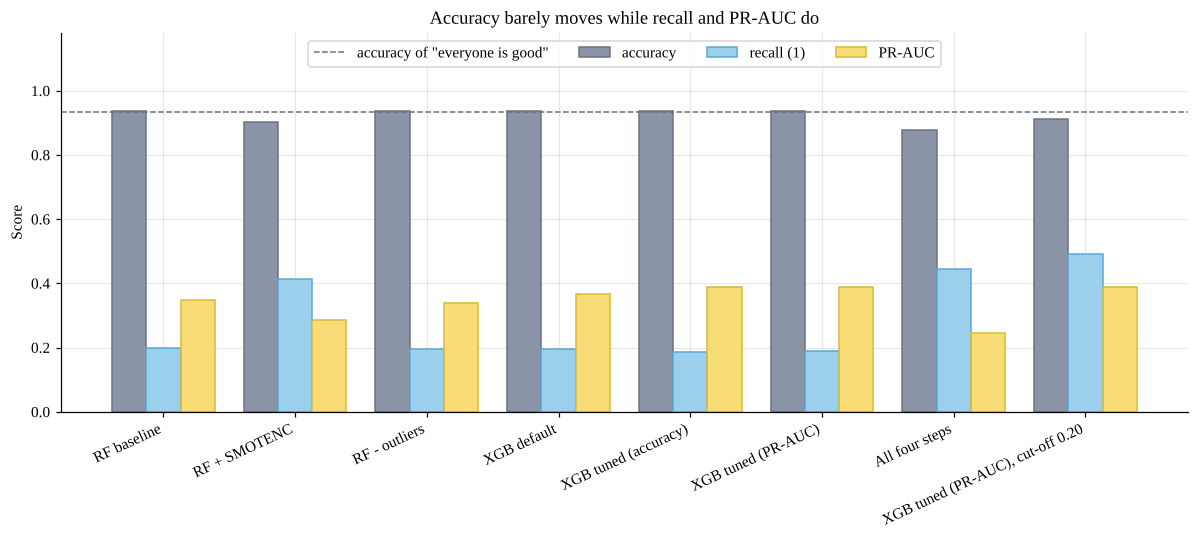

In [15]:
metrics = ['accuracy', 'recall (1)', 'PR-AUC']
colors = [GRAY, SKY, YELLOW]
edges = ['#6B7280', SKY_EDGE, YELLOW_EDGE]
fig, ax = plt.subplots(figsize=(11, 5))
w = 0.26
x = np.arange(len(summary))
for i, (m, c, e) in enumerate(zip(metrics, colors, edges)):
    ax.bar(x + (i - 1) * w, summary[m], w, color=c, edgecolor=e, label=m)
ax.axhline(1 - y_test.mean(), color='#6B7280', linestyle='--', linewidth=1, label='accuracy of "everyone is good"')
ax.set_xticks(x, summary.index, rotation=25, ha='right')
ax.set_ylabel('Score')
ax.set_title('Accuracy barely moves while recall and PR-AUC do')
ax.set_ylim(0, 1.18)
ax.legend(loc='upper center', ncol=4)
plt.tight_layout()
plt.show()

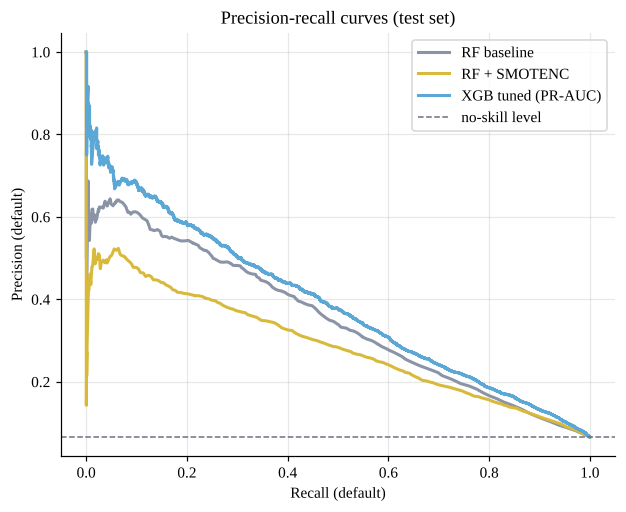

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for key, color in [('RF baseline', GRAY), ('RF + SMOTENC', YELLOW_EDGE), ('XGB tuned (PR-AUC)', SKY_EDGE)]:
    p, r, _ = precision_recall_curve(y_test, probas[key])
    ax.plot(r, p, color=color, linewidth=2, label=key)
ax.axhline(y_test.mean(), color='#6B7280', linestyle='--', linewidth=1, label='no-skill level')
ax.set_xlabel('Recall (default)')
ax.set_ylabel('Precision (default)')
ax.set_title('Precision-recall curves (test set)')
ax.legend()
plt.show()

### **Q4 (c) · Result**

In [17]:
best_row = summary.loc[f'XGB tuned (PR-AUC), cut-off {cut:.2f}']
acc_row = summary.loc['XGB tuned (accuracy)']
print('Best model for finding defaulters: XGBoost')
print('Hyperparameters (chosen by 3-fold CV on PR-AUC):', searches['average_precision'].best_params_)
print(f"  at cut-off {cut:.2f}: accuracy {best_row['accuracy']:.4f}, recall {best_row['recall (1)']:.3f}, "
      f"precision {best_row['precision (1)']:.3f}, F1 {best_row['F1 (1)']:.3f}, PR-AUC {best_row['PR-AUC']:.3f}")
print()
print('Best model by accuracy alone:', searches['accuracy'].best_params_)
print(f"  accuracy {acc_row['accuracy']:.4f} (baseline RF {summary.loc['RF baseline', 'accuracy']:.4f}, "
      f"everyone-is-good {1 - y_test.mean():.4f}), recall {acc_row['recall (1)']:.3f}")

Best model for finding defaulters: XGBoost
Hyperparameters (chosen by 3-fold CV on PR-AUC): {'subsample': 0.9, 'reg_lambda': 10, 'min_child_weight': 20, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
  at cut-off 0.20: accuracy 0.9130, recall 0.491, precision 0.378, F1 0.427, PR-AUC 0.387

Best model by accuracy alone: {'subsample': 1.0, 'reg_lambda': 1, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
  accuracy 0.9380 (baseline RF 0.9360, everyone-is-good 0.9340), recall 0.185


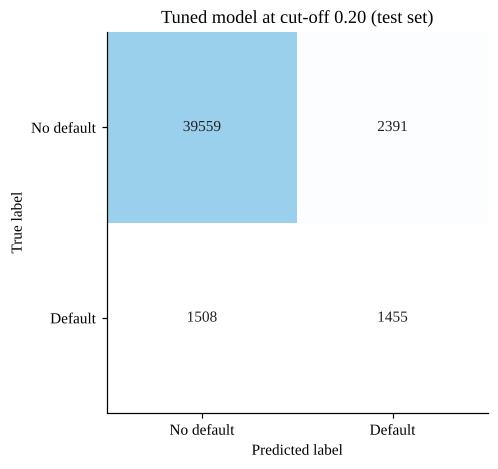

In [18]:
cm_best = confusion_matrix(y_test, probas['XGB tuned (PR-AUC)'] >= cut)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm_best, display_labels=['No default', 'Default']).plot(
    ax=ax, cmap=PASTEL, colorbar=False, values_format='d')
ax.grid(False)
for t in ax.texts:
    t.set_color('#222222')
ax.set_title(f'Tuned model at cut-off {cut:.2f} (test set)')
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
plt.show()